# Лабораторна робота № 3
## Знайомство з нейронними мережами

**Мета:** ознайомитися з побудовою та навчанням нейронних мереж для табличних даних, зображень і текстів за допомогою PyTorch; порівняти нейромережеві підходи з класичними алгоритмами машинного навчання.

## 0. Підготовка середовища

У роботі використано:
- **табличні дані:** Cybersecurity Intrusion Detection Dataset з лабораторної № 1;
- **зображення:** Oxford-IIIT Pet Dataset (37 класів домашніх тварин; не MNIST і не CIFAR-10);
- **тексти:** SMS Spam Collection з лабораторної № 2.

Для відтворюваності фіксуємо генератори випадкових чисел. Для завантаження табличного CSV передбачено пошук у типовому каталозі Colab або ручне завантаження файла.

In [4]:
!pip -q install torch torchvision scikit-learn pandas matplotlib seaborn

In [5]:
import os, re, random, zipfile, urllib.request, time, copy, math
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Пристрій:", device)

Пристрій: cuda


# 1. Повнозв'язана нейронна мережа (MLP) для табличних даних

Використовується той самий датасет, що й у лабораторній № 1. Цільова змінна — `attack_detected`: 0 означає відсутність атаки, 1 — наявність атаки. Ідентифікатор `session_id` не є корисною ознакою для узагальнення, тому його вилучаємо.

Категоріальні ознаки кодуємо One-Hot Encoding, числові масштабуємо за допомогою StandardScaler. Пропущені значення заповнюємо найбільш частим значенням для категоріальних ознак і медіаною для числових.

In [6]:
# Якщо файл уже завантажений у Colab, код спробує знайти його автоматично.
# За потреби вкажіть власний шлях у CSV_PATH.
CSV_PATH = "/content/cybersecurity_intrusion_data.csv"

if not os.path.exists(CSV_PATH):
    from google.colab import files
    print("Завантажте CSV датасету з лабораторної №1.")
    uploaded = files.upload()
    CSV_PATH = next(iter(uploaded.keys()))

df = pd.read_csv(CSV_PATH)
print("Розмір:", df.shape)
display(df.head())
print(df.dtypes)
print("Пропущені значення:\n", df.isna().sum())

Завантажте CSV датасету з лабораторної №1.


Saving cybersecurity_intrusion_data.csv to cybersecurity_intrusion_data.csv
Розмір: (9537, 11)


,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0


session_id              object
network_packet_size      int64
protocol_type           object
login_attempts           int64
session_duration       float64
encryption_used         object
ip_reputation_score    float64
failed_logins            int64
browser_type            object
unusual_time_access      int64
attack_detected          int64
dtype: object
Пропущені значення:
 session_id                0
network_packet_size       0
protocol_type             0
login_attempts            0
session_duration          0
encryption_used        1966
ip_reputation_score       0
failed_logins             0
browser_type              0
unusual_time_access       0
attack_detected           0
dtype: int64


In [7]:
TARGET = "attack_detected"
assert TARGET in df.columns, f"У датасеті має бути колонка {TARGET}"
df = df.drop(columns=["session_id"], errors="ignore")
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20, random_state=SEED, stratify=y_train_full
)

X_train = preprocessor.fit_transform(X_train).astype(np.float32)
X_val = preprocessor.transform(X_val).astype(np.float32)
X_test = preprocessor.transform(X_test).astype(np.float32)

# PyTorch Linear очікує щільний масив, тому розріджене one-hot подання перетворюємо.
if hasattr(X_train, "toarray"):
    X_train = X_train.toarray()
    X_val = X_val.toarray()
    X_test = X_test.toarray()

y_train = y_train.to_numpy(dtype=np.float32)
y_val = y_val.to_numpy(dtype=np.float32)
y_test = y_test.to_numpy(dtype=np.float32)

print("Train / validation / test:", X_train.shape, X_val.shape, X_test.shape)

Train / validation / test: (6103, 16) (1526, 16) (1908, 16)


## 1.1 Архітектура та навчання MLP

Мережа має вхідний шар, два приховані повнозв'язані шари з ReLU та Dropout, а також один вихідний нейрон. На виході використовується логіт (без Sigmoid у самій моделі), оскільки `BCEWithLogitsLoss` поєднує сигмоїду та бінарну крос-ентропію чисельно стабільним способом.

In [8]:
class TabularMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

def make_tensor_loader(X, y, batch_size=128, shuffle=False):
    ds = torch.utils.data.TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32).view(-1, 1)
    )
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

train_loader = make_tensor_loader(X_train, y_train, shuffle=True)
val_loader = make_tensor_loader(X_val, y_val)
test_loader = make_tensor_loader(X_test, y_test)

mlp = TabularMLP(X_train.shape[1]).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-4)

def run_binary_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, n = 0.0, 0
    all_y, all_p = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        if training: optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(xb); n += len(xb)
        all_y.extend(yb.detach().cpu().numpy().ravel())
        all_p.extend(torch.sigmoid(logits).detach().cpu().numpy().ravel())
    return total_loss/n, np.array(all_y), np.array(all_p)

def train_binary(model, train_loader, val_loader, epochs=30, patience=6):
    history = {"train_loss": [], "val_loss": []}
    best_loss, best_state, wait = float("inf"), None, 0
    for epoch in range(epochs):
        tr_loss, _, _ = run_binary_epoch(model, train_loader, optimizer)
        va_loss, _, _ = run_binary_epoch(model, val_loader)
        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        print(f"Epoch {epoch+1:02d}: train={tr_loss:.4f}, val={va_loss:.4f}")
        if va_loss < best_loss:
            best_loss, best_state, wait = va_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping"); break
    if best_state: model.load_state_dict(best_state)
    return history

start = time.time()
mlp_history = train_binary(mlp, train_loader, val_loader)
mlp_time = time.time() - start

Epoch 01: train=0.6420, val=0.5682
Epoch 02: train=0.5331, val=0.4844
Epoch 03: train=0.4898, val=0.4466
Epoch 04: train=0.4555, val=0.4104
Epoch 05: train=0.4274, val=0.3843
Epoch 06: train=0.4059, val=0.3665
Epoch 07: train=0.3939, val=0.3536
Epoch 08: train=0.3776, val=0.3446
Epoch 09: train=0.3695, val=0.3367
Epoch 10: train=0.3628, val=0.3315
Epoch 11: train=0.3529, val=0.3267
Epoch 12: train=0.3472, val=0.3217
Epoch 13: train=0.3432, val=0.3187
Epoch 14: train=0.3389, val=0.3134
Epoch 15: train=0.3332, val=0.3092
Epoch 16: train=0.3283, val=0.3062
Epoch 17: train=0.3274, val=0.3032
Epoch 18: train=0.3225, val=0.3043
Epoch 19: train=0.3232, val=0.3047
Epoch 20: train=0.3158, val=0.2984
Epoch 21: train=0.3160, val=0.2994
Epoch 22: train=0.3153, val=0.2972
Epoch 23: train=0.3107, val=0.2950
Epoch 24: train=0.3079, val=0.2940
Epoch 25: train=0.3075, val=0.2947
Epoch 26: train=0.3071, val=0.2923
Epoch 27: train=0.3050, val=0.2923
Epoch 28: train=0.3071, val=0.2913
Epoch 29: train=0.30

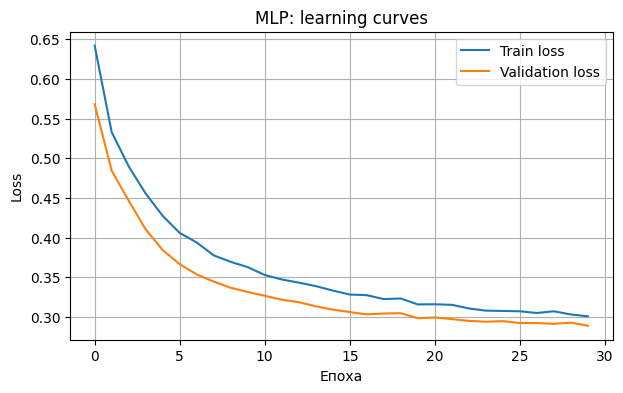

              precision    recall  f1-score   support

         0.0     0.8278    0.9934    0.9031      1055
         1.0     0.9891    0.7444    0.8495       853

    accuracy                         0.8821      1908
   macro avg     0.9085    0.8689    0.8763      1908
weighted avg     0.8999    0.8821    0.8791      1908

MLP accuracy=0.8821, precision=0.9891, recall=0.7444, F1=0.8495
Час навчання: 12.3 с


In [9]:
plt.figure(figsize=(7,4))
plt.plot(mlp_history["train_loss"], label="Train loss")
plt.plot(mlp_history["val_loss"], label="Validation loss")
plt.xlabel("Епоха"); plt.ylabel("Loss"); plt.title("MLP: learning curves")
plt.legend(); plt.grid(True); plt.show()

_, y_true_mlp, p_mlp = run_binary_epoch(mlp, test_loader)
pred_mlp = (p_mlp >= 0.5).astype(int)
mlp_acc = accuracy_score(y_true_mlp, pred_mlp)
mlp_p, mlp_r, mlp_f1, _ = precision_recall_fscore_support(
    y_true_mlp, pred_mlp, average="binary", zero_division=0
)
print(classification_report(y_true_mlp, pred_mlp, digits=4))
print(f"MLP accuracy={mlp_acc:.4f}, precision={mlp_p:.4f}, recall={mlp_r:.4f}, F1={mlp_f1:.4f}")
print(f"Час навчання: {mlp_time:.1f} с")

## 1.2 Порівняння з класичними алгоритмами Lab 1

У лабораторній № 1 були отримані такі результати на цьому датасеті: kNN (k=15) — accuracy 0.8241; Decision Tree — 0.8270; SVM (C=10, gamma=0.1) — 0.8810; Random Forest — 0.8831; AdaBoost — 0.8643. Нижче додаємо фактичну точність MLP після запуску.

In [10]:
classical_results = {
    "kNN (k=15)": 0.8241,
    "Decision Tree": 0.8270,
    "SVM": 0.8810,
    "Random Forest": 0.8831,
    "AdaBoost": 0.8643,
    "MLP (PyTorch)": mlp_acc
}
pd.Series(classical_results, name="Test accuracy").sort_values(ascending=False).to_frame()

,Test accuracy
Random Forest,0.883100
MLP (PyTorch),0.882075
SVM,0.881000
AdaBoost,0.864300
Decision Tree,0.827000
kNN (k=15),0.824100


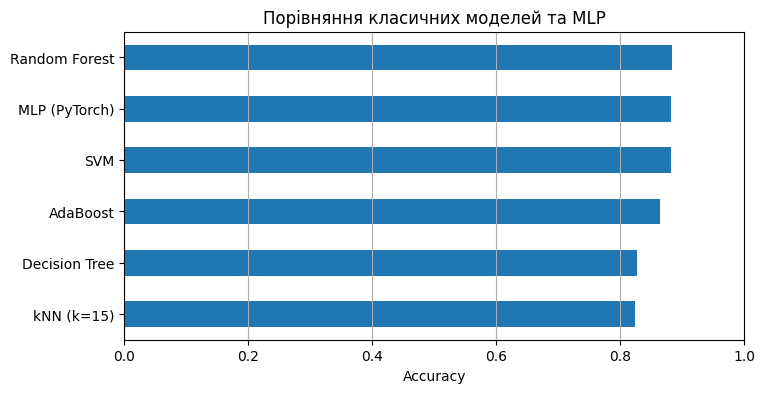

In [11]:
plt.figure(figsize=(8,4))
pd.Series(classical_results).sort_values().plot(kind="barh")
plt.xlabel("Accuracy"); plt.title("Порівняння класичних моделей та MLP")
plt.xlim(0,1); plt.grid(axis="x"); plt.show()

**Інтерпретація:** порівнюйте не лише accuracy, а й precision, recall та F1. Для виявлення атак особливо важливий recall класу 1, оскільки він показує, яку частку реальних атак модель виявила. Якщо train loss продовжує зменшуватися, а validation loss зростає, це ознака перенавчання. Якщо обидві криві зменшуються та зближуються, навчання проходить стабільніше.

# 2. Згорткові нейронні мережі (CNN) для класифікації зображень

Використовується **Oxford-IIIT Pet Dataset**. Датасет містить фотографії котів і собак, розподілені на 37 порід-класів. Він доступний у `torchvision` і не є MNIST або CIFAR-10. У коді створюються навчальна, валідаційна та тестова вибірки. Для обмеження часу зображення масштабуються до 128×128.

In [12]:
from torchvision import datasets, transforms, models
from torchvision.models import ResNet18_Weights
from torch.utils.data import Subset

IMG_SIZE = 128
img_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

# Завантаження зображень; перший запуск може тривати кілька хвилин.
pet_trainval = datasets.OxfordIIITPet(root="/content/data", split="trainval",
                                      target_types="category", download=True,
                                      transform=img_transform)
pet_test = datasets.OxfordIIITPet(root="/content/data", split="test",
                                  target_types="category", download=True,
                                  transform=img_transform)
class_names = pet_trainval.classes
num_classes = len(class_names)
print("Кількість класів:", num_classes)
print("Trainval images:", len(pet_trainval), "| Test images:", len(pet_test))
print(class_names)

100%|██████████| 792M/792M [00:37<00:00, 21.0MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 8.65MB/s]


Кількість класів: 37
Trainval images: 3680 | Test images: 3669
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']


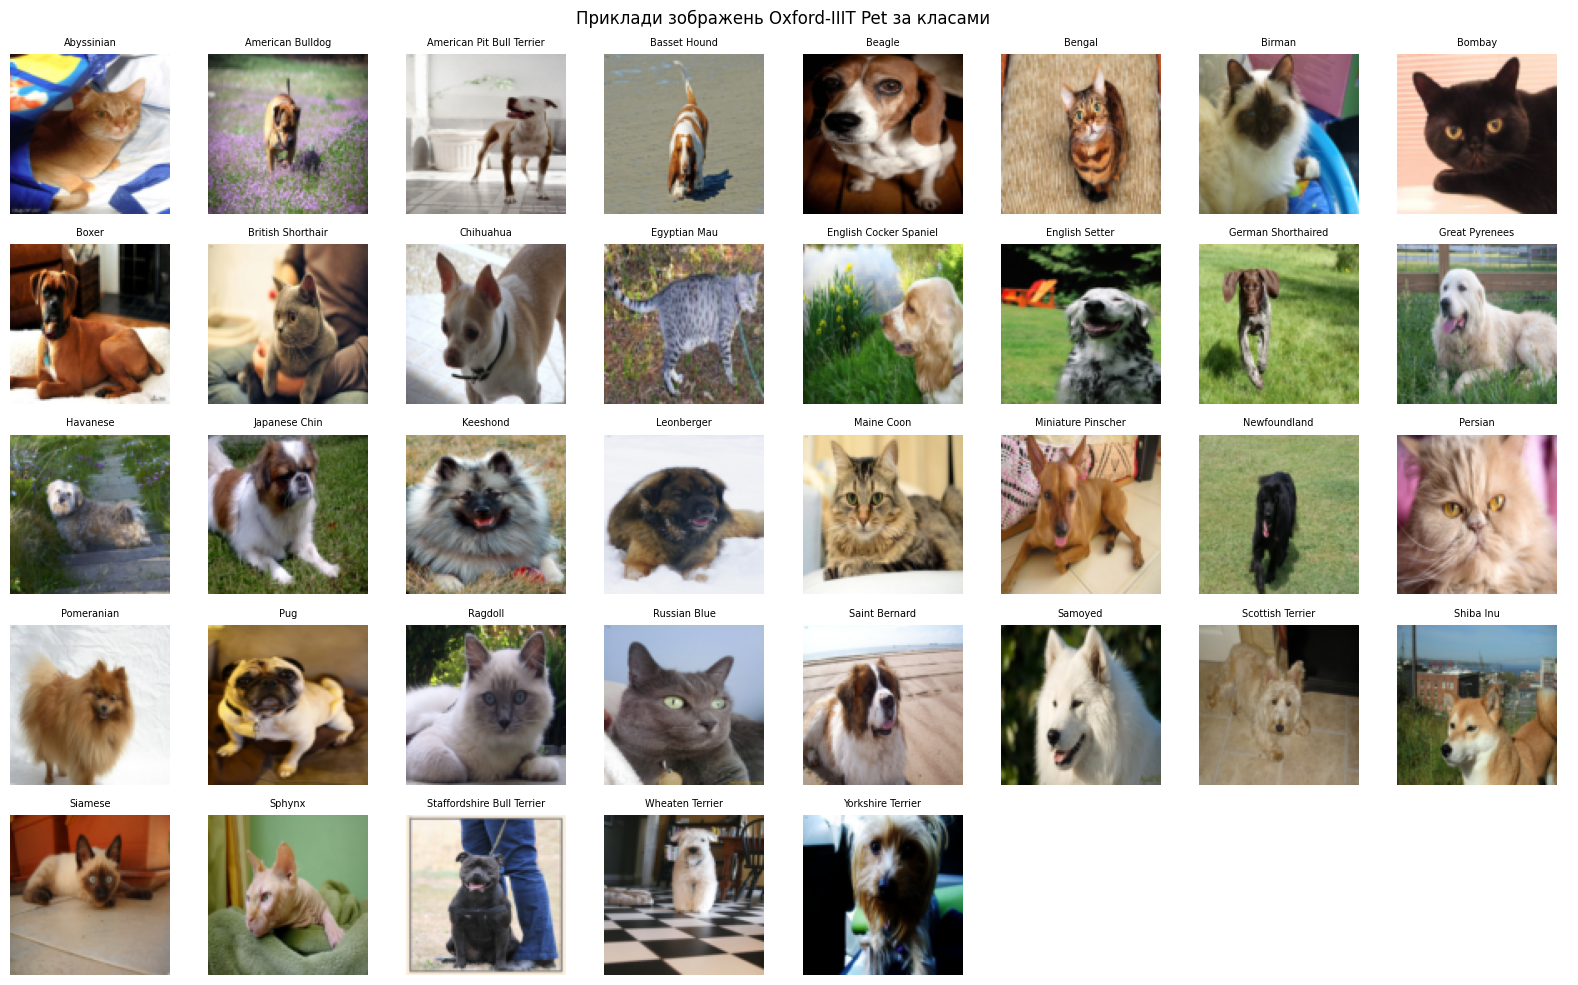

In [13]:
# Візуалізація прикладу для кожного класу (по одному зображенню на клас).
# Для зручності використовується оригінальний набір без нормалізації.
preview_ds = datasets.OxfordIIITPet(root="/content/data", split="trainval",
                                    target_types="category", download=False,
                                    transform=transforms.Compose([
                                        transforms.Resize((96,96)), transforms.ToTensor()
                                    ]))
chosen = {}
for idx, (_, label) in enumerate(preview_ds):
    if label not in chosen: chosen[label] = idx
    if len(chosen) == num_classes: break

fig, axes = plt.subplots(5, 8, figsize=(16,10))
for ax in axes.flat: ax.axis("off")
for ax, (label, idx) in zip(axes.flat, sorted(chosen.items())):
    img, _ = preview_ds[idx]
    ax.imshow(img.permute(1,2,0))
    ax.set_title(class_names[label], fontsize=7)
    ax.axis("off")
plt.suptitle("Приклади зображень Oxford-IIIT Pet за класами")
plt.tight_layout(); plt.show()

In [14]:
# Стратифікований поділ індексів trainval на train і validation.
targets = np.array(pet_trainval._labels)
all_idx = np.arange(len(targets))
tr_idx, va_idx = train_test_split(all_idx, test_size=0.20, random_state=SEED, stratify=targets)
train_img_ds = Subset(pet_trainval, tr_idx)
val_img_ds = Subset(pet_trainval, va_idx)

BATCH_SIZE = 64
train_img_loader = DataLoader(train_img_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_img_loader = DataLoader(val_img_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_img_loader = DataLoader(pet_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
print(len(train_img_ds), len(val_img_ds), len(pet_test))

2944 736 3669


## 2.1 CNN, навчена з нуля

Архітектура містить три згорткові блоки. Згорткові шари навчаються виділяти локальні ознаки зображення (контури, текстури, частини об'єктів), pooling зменшує просторовий розмір, а повнозв'язаний шар формує прогноз для 37 класів.

In [15]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1,1))
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

def train_multiclass(model, train_loader, val_loader, epochs=8, lr=1e-3, patience=3):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best, state, wait = float("inf"), None, 0
    for ep in range(epochs):
        row = {}
        for phase, loader in [("train", train_loader), ("val", val_loader)]:
            model.train(phase=="train")
            total_loss, correct, total = 0., 0, 0
            for xb, yb in loader:
                xb, yb = xb.to(device), yb.to(device)
                if phase=="train": opt.zero_grad()
                with torch.set_grad_enabled(phase=="train"):
                    logits = model(xb); loss = loss_fn(logits, yb)
                    if phase=="train":
                        loss.backward(); opt.step()
                total_loss += loss.item()*len(xb)
                correct += (logits.argmax(1)==yb).sum().item(); total += len(xb)
            row[phase+"_loss"] = total_loss/total
            row[phase+"_acc"] = correct/total
        for k,v in row.items(): hist[k].append(v)
        print(f"Epoch {ep+1}: train loss {row['train_loss']:.4f}, val loss {row['val_loss']:.4f}, "
              f"train acc {row['train_acc']:.3f}, val acc {row['val_acc']:.3f}")
        if row["val_loss"] < best:
            best, state, wait = row["val_loss"], copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience: print("Early stopping"); break
    if state: model.load_state_dict(state)
    return model, hist

def evaluate_multiclass(model, loader):
    model.eval(); ys=[]; ps=[]
    with torch.no_grad():
        for xb,yb in loader:
            logits=model(xb.to(device))
            ps.extend(logits.argmax(1).cpu().numpy()); ys.extend(yb.numpy())
    acc=accuracy_score(ys,ps)
    return acc, np.array(ys), np.array(ps)

cnn = SimpleCNN(num_classes)
start=time.time()
cnn, cnn_hist = train_multiclass(cnn, train_img_loader, val_img_loader, epochs=8, lr=1e-3)
cnn_time=time.time()-start

Epoch 1: train loss 3.6116, val loss 3.5961, train acc 0.031, val acc 0.035
Epoch 2: train loss 3.5870, val loss 3.5697, train acc 0.040, val acc 0.049
Epoch 3: train loss 3.5588, val loss 3.5528, train acc 0.048, val acc 0.048
Epoch 4: train loss 3.5485, val loss 3.5231, train acc 0.053, val acc 0.057
Epoch 5: train loss 3.5208, val loss 3.5138, train acc 0.054, val acc 0.077
Epoch 6: train loss 3.5097, val loss 3.5119, train acc 0.059, val acc 0.073
Epoch 7: train loss 3.4913, val loss 3.4812, train acc 0.071, val acc 0.072
Epoch 8: train loss 3.4650, val loss 3.4752, train acc 0.069, val acc 0.062


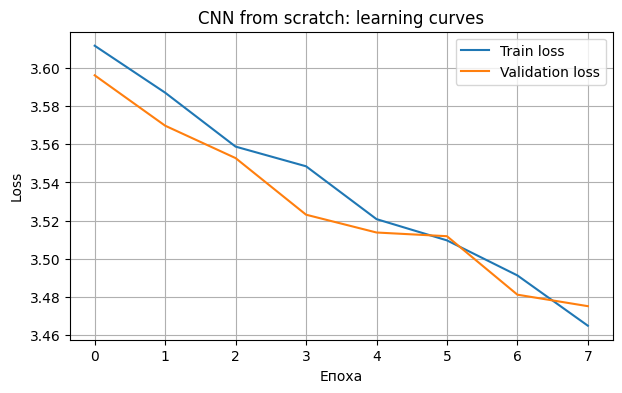

CNN test accuracy: 0.0605; training time: 117.7 s


In [16]:
def plot_history(hist, title):
    plt.figure(figsize=(7,4))
    plt.plot(hist["train_loss"], label="Train loss")
    plt.plot(hist["val_loss"], label="Validation loss")
    plt.xlabel("Епоха"); plt.ylabel("Loss"); plt.title(title)
    plt.legend(); plt.grid(True); plt.show()

plot_history(cnn_hist, "CNN from scratch: learning curves")
cnn_acc, y_cnn, p_cnn = evaluate_multiclass(cnn, test_img_loader)
print(f"CNN test accuracy: {cnn_acc:.4f}; training time: {cnn_time:.1f} s")

## 2.2 Попередньо натренована ResNet18

ResNet18 попередньо навчена на ImageNet. Замість її стандартного класифікатора встановлюється новий шар на 37 виходів. Спочатку заморожується основна частина мережі й навчається класифікатор, після чого розморожується останній блок `layer4` для обережного донавчання.

In [17]:
weights = ResNet18_Weights.DEFAULT
resnet = models.resnet18(weights=weights)
for param in resnet.parameters():
    param.requires_grad = False
resnet.fc = nn.Linear(resnet.fc.in_features, num_classes)
for param in resnet.layer4.parameters():
    param.requires_grad = True
for param in resnet.fc.parameters():
    param.requires_grad = True

# Окремі learning rates: менший для pretrained layer4, більший для нового класифікатора.
loss_fn = nn.CrossEntropyLoss()
optimizer_res = torch.optim.Adam([
    {"params": resnet.layer4.parameters(), "lr": 1e-4},
    {"params": resnet.fc.parameters(), "lr": 1e-3}
])
# Та сама функція навчання, але оптимізатор передаємо явно.
def train_resnet(model, train_loader, val_loader, epochs=6, patience=3):
    model=model.to(device)
    hist={"train_loss":[],"val_loss":[],"train_acc":[],"val_acc":[]}
    best=float("inf"); state=None; wait=0
    for ep in range(epochs):
        row={}
        for phase,loader in [("train",train_loader),("val",val_loader)]:
            model.train(phase=="train")
            total_loss=0.; correct=0; total=0
            for xb,yb in loader:
                xb,yb=xb.to(device),yb.to(device)
                if phase=="train": optimizer_res.zero_grad()
                with torch.set_grad_enabled(phase=="train"):
                    logits=model(xb); loss=loss_fn(logits,yb)
                    if phase=="train": loss.backward(); optimizer_res.step()
                total_loss+=loss.item()*len(xb); correct+=(logits.argmax(1)==yb).sum().item(); total+=len(xb)
            row[phase+"_loss"]=total_loss/total; row[phase+"_acc"]=correct/total
        for k,v in row.items(): hist[k].append(v)
        print(f"Epoch {ep+1}: train loss {row['train_loss']:.4f}, val loss {row['val_loss']:.4f}, "
              f"train acc {row['train_acc']:.3f}, val acc {row['val_acc']:.3f}")
        if row["val_loss"]<best:
            best=row["val_loss"]; state=copy.deepcopy(model.state_dict()); wait=0
        else:
            wait+=1
            if wait>=patience: print("Early stopping"); break
    if state: model.load_state_dict(state)
    return model,hist

start=time.time()
resnet,resnet_hist=train_resnet(resnet,train_img_loader,val_img_loader,epochs=6)
resnet_time=time.time()-start

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 208MB/s]


Epoch 1: train loss 2.1176, val loss 1.0977, train acc 0.462, val acc 0.701
Epoch 2: train loss 0.5806, val loss 0.8619, train acc 0.874, val acc 0.728
Epoch 3: train loss 0.2075, val loss 0.7964, train acc 0.978, val acc 0.743
Epoch 4: train loss 0.0751, val loss 0.7668, train acc 0.999, val acc 0.753
Epoch 5: train loss 0.0359, val loss 0.7612, train acc 1.000, val acc 0.755
Epoch 6: train loss 0.0212, val loss 0.7600, train acc 1.000, val acc 0.761


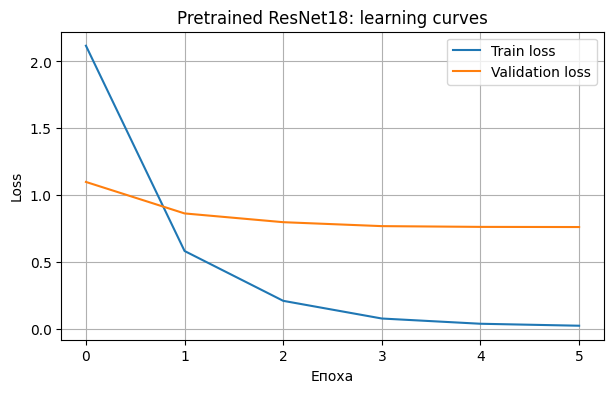

ResNet18 test accuracy: 0.7441; fine-tuning time: 78.6 s


,Модель,Test accuracy,"Час навчання, с"
0,CNN з нуля,0.060507,117.748634
1,Pretrained ResNet18,0.744072,78.579729


In [18]:
plot_history(resnet_hist, "Pretrained ResNet18: learning curves")
resnet_acc, y_res, p_res = evaluate_multiclass(resnet, test_img_loader)
print(f"ResNet18 test accuracy: {resnet_acc:.4f}; fine-tuning time: {resnet_time:.1f} s")

comparison_images = pd.DataFrame({
    "Модель":["CNN з нуля","Pretrained ResNet18"],
    "Test accuracy":[cnn_acc,resnet_acc],
    "Час навчання, с":[cnn_time,resnet_time]
})
display(comparison_images)

**Аналіз:** pretrained модель має перевагу попередньо засвоєних ознак із великого ImageNet, тому часто досягає кращої якості за меншу кількість епох. CNN з нуля повинна самостійно навчитися виділяти ознаки, тому за обмеженого датасету може навчатися повільніше та бути схильнішою до перенавчання. Фактичний висновок потрібно сформулювати за отриманими accuracy, кривими loss і часом навчання. Вплив обсягу даних можна оцінити додатковим експериментом нижче.

In [19]:
# Додатковий експеримент: навчання простої CNN на 25% тренувальних прикладів.
small_n=max(1,int(0.25*len(tr_idx)))
small_subset=Subset(pet_trainval, tr_idx[:small_n])
small_loader=DataLoader(small_subset,batch_size=BATCH_SIZE,shuffle=True,num_workers=2)
small_cnn=SimpleCNN(num_classes)
start=time.time()
small_cnn,small_hist=train_multiclass(small_cnn,small_loader,val_img_loader,epochs=5,lr=1e-3,patience=2)
small_time=time.time()-start
small_acc,_,_=evaluate_multiclass(small_cnn,test_img_loader)
print(f"25% train data: test accuracy={small_acc:.4f}; time={small_time:.1f}s")

Epoch 1: train loss 3.6220, val loss 3.6125, train acc 0.014, val acc 0.030
Epoch 2: train loss 3.6041, val loss 3.6110, train acc 0.026, val acc 0.030
Epoch 3: train loss 3.5920, val loss 3.6187, train acc 0.038, val acc 0.029
Epoch 4: train loss 3.5790, val loss 3.6149, train acc 0.042, val acc 0.033
Early stopping
25% train data: test accuracy=0.0234; time=21.7s


# 3. Нейронні мережі для класифікації текстів

Використовується SMS Spam Collection з лабораторної № 2. Цільова задача — класифікація повідомлення як `ham` (звичайне повідомлення) або `spam` (спам). Текст очищується, токенізується, перетворюється на індекси словника, а послідовності приводяться до фіксованої довжини за допомогою padding/truncation.

In [21]:
# Шлях з лабораторної №2. Якщо файл відсутній, завантажте SMSSpamCollection у Colab.
SMS_PATH="/content/drive/MyDrive/Colab Notebooks/SMSSpamCollection"
if not os.path.exists(SMS_PATH):
    from google.colab import drive
    drive.mount('/content/drive')
if not os.path.exists(SMS_PATH):
    from google.colab import files
    print("Завантажте файл SMSSpamCollection.")
    uploaded=files.upload()
    SMS_PATH=next(iter(uploaded.keys()))

# У стандартному файлі SMS Spam Collection немає заголовка: label<TAB>message.
sms=pd.read_csv(SMS_PATH,sep="\t",header=None,names=["label","text"],encoding="latin-1")
sms=sms.dropna()
sms["label"]=sms["label"].map({"ham":0,"spam":1})
sms=sms.dropna(subset=["label"])
sms["label"]=sms["label"].astype(int)
print(sms.shape); display(sms.head()); print(sms["label"].value_counts())

Mounted at /content/drive
(5572, 2)


,label,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


label
0    4825
1     747
Name: count, dtype: int64


## 3.1 Токенізація, словник і padding

Токенізація розбиває повідомлення на слова й прості числові/літерні токени. Індекс 0 резервується для padding, індекс 1 — для невідомих слів (`UNK`). Словник будується лише за тренувальними текстами, щоб не використовувати інформацію з тестової вибірки.

In [22]:
def tokenize(text):
    return re.findall(r"[a-z0-9']+", str(text).lower())

texts=sms["text"].tolist()
labels=sms["label"].to_numpy()
train_ids,test_ids=train_test_split(np.arange(len(texts)),test_size=0.20,random_state=SEED,stratify=labels)
train_ids,val_ids=train_test_split(train_ids,test_size=0.20,random_state=SEED,stratify=labels[train_ids])

tokenized=[tokenize(t) for t in texts]
counter=Counter(tok for i in train_ids for tok in tokenized[i])
MAX_VOCAB=12000
vocab={"<PAD>":0,"<UNK>":1}
for word,_ in counter.most_common(MAX_VOCAB-2):
    vocab[word]=len(vocab)

MAX_LEN=60
def encode(tokens):
    ids=[vocab.get(t,1) for t in tokens[:MAX_LEN]]
    return ids+[0]*(MAX_LEN-len(ids))

X_text=np.array([encode(t) for t in tokenized],dtype=np.int64)
y_text=labels.astype(np.int64)
print("Vocabulary size:",len(vocab)," | Sequence length:",MAX_LEN)
print("Example tokens:",tokenized[0][:15])
print("Example indices:",X_text[0][:20])

Vocabulary size: 6983  | Sequence length: 60
Example tokens: ['go', 'until', 'jurong', 'point', 'crazy', 'available', 'only', 'in', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet']
Example indices: [  52  411 6750  919 1414  652   68    9 1613   85  107  420 1093  135
 2890 1988   65   56 6751  127]


In [23]:
class SMSDataset(Dataset):
    def __init__(self, indices):
        self.x=torch.tensor(X_text[indices],dtype=torch.long)
        self.y=torch.tensor(y_text[indices],dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self,i): return self.x[i],self.y[i]

train_text_loader=DataLoader(SMSDataset(train_ids),batch_size=64,shuffle=True)
val_text_loader=DataLoader(SMSDataset(val_ids),batch_size=64)
test_text_loader=DataLoader(SMSDataset(test_ids),batch_size=64)

## 3.2 GRU з випадково ініціалізованим Embedding

Embedding перетворює кожен індекс слова на щільний вектор розмірності 64. Спочатку ваги embedding випадкові й навчаються разом із GRU. GRU обробляє послідовність токенів і формує прихований стан, який використовується для бінарної класифікації.

In [24]:
class TextGRU(nn.Module):
    def __init__(self,vocab_size,emb_dim=64,hidden=64,pretrained_matrix=None,freeze=False):
        super().__init__()
        self.embedding=nn.Embedding(vocab_size,emb_dim,padding_idx=0)
        if pretrained_matrix is not None:
            self.embedding.weight.data.copy_(torch.tensor(pretrained_matrix,dtype=torch.float32))
            self.embedding.weight.requires_grad=not freeze
        self.gru=nn.GRU(emb_dim,hidden,batch_first=True)
        self.dropout=nn.Dropout(0.3)
        self.fc=nn.Linear(hidden,2)
    def forward(self,x):
        emb=self.embedding(x)
        _,h=self.gru(emb)
        return self.fc(self.dropout(h[-1]))

def train_text_model(model,epochs=10,lr=1e-3,patience=3):
    model=model.to(device); loss_fn=nn.CrossEntropyLoss()
    opt=torch.optim.Adam(filter(lambda p:p.requires_grad,model.parameters()),lr=lr)
    hist={"train_loss":[],"val_loss":[]}
    best=float("inf"); state=None; wait=0
    for ep in range(epochs):
        row={}
        for phase,loader in [("train",train_text_loader),("val",val_text_loader)]:
            model.train(phase=="train"); total_loss=0.; total=0
            for xb,yb in loader:
                xb,yb=xb.to(device),yb.to(device)
                if phase=="train": opt.zero_grad()
                with torch.set_grad_enabled(phase=="train"):
                    logits=model(xb); loss=loss_fn(logits,yb)
                    if phase=="train": loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
                total_loss+=loss.item()*len(xb); total+=len(xb)
            row[phase+"_loss"]=total_loss/total
        for k,v in row.items(): hist[k].append(v)
        print(f"Epoch {ep+1}: train loss={row['train_loss']:.4f}, val loss={row['val_loss']:.4f}")
        if row["val_loss"]<best:
            best=row["val_loss"]; state=copy.deepcopy(model.state_dict()); wait=0
        else:
            wait+=1
            if wait>=patience: print("Early stopping"); break
    if state: model.load_state_dict(state)
    return model,hist

def evaluate_text(model,loader):
    model.eval(); ys=[]; ps=[]
    with torch.no_grad():
        for xb,yb in loader:
            pred=model(xb.to(device)).argmax(1).cpu().numpy()
            ps.extend(pred); ys.extend(yb.numpy())
    acc=accuracy_score(ys,ps)
    pr,re_,f1,_=precision_recall_fscore_support(ys,ps,average="binary",zero_division=0)
    return acc,pr,re_,f1,ys,ps

gru_random=TextGRU(len(vocab))
start=time.time()
gru_random,gru_random_hist=train_text_model(gru_random,epochs=10)
gru_random_time=time.time()-start

Epoch 1: train loss=0.4756, val loss=0.3956
Epoch 2: train loss=0.3990, val loss=0.3988
Epoch 3: train loss=0.3941, val loss=0.3934
Epoch 4: train loss=0.3630, val loss=0.3294
Epoch 5: train loss=0.2272, val loss=0.2841
Epoch 6: train loss=0.1237, val loss=0.1859
Epoch 7: train loss=0.0847, val loss=0.1959
Epoch 8: train loss=0.0641, val loss=0.1854
Epoch 9: train loss=0.0487, val loss=0.2232
Epoch 10: train loss=0.0396, val loss=0.1865


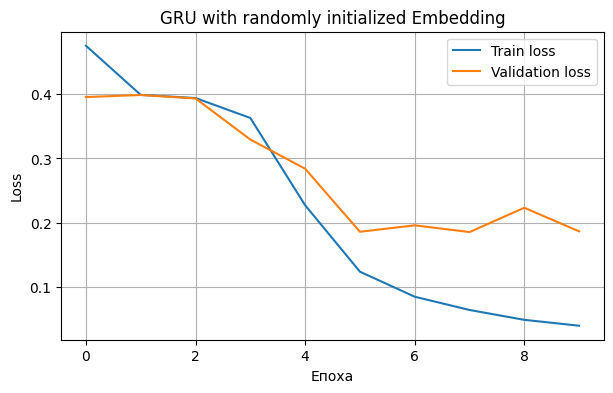

Random embedding: accuracy, precision, recall, F1 = (0.9506726457399103, 0.8790322580645161, 0.7315436241610739, 0.7985347985347986)
              precision    recall  f1-score   support

         ham     0.9596    0.9845    0.9719       966
        spam     0.8790    0.7315    0.7985       149

    accuracy                         0.9507      1115
   macro avg     0.9193    0.8580    0.8852      1115
weighted avg     0.9489    0.9507    0.9487      1115



In [25]:
plot_history(gru_random_hist,"GRU with randomly initialized Embedding")
rand_metrics=evaluate_text(gru_random,test_text_loader)
print("Random embedding: accuracy, precision, recall, F1 =",rand_metrics[:4])
print(classification_report(rand_metrics[4],rand_metrics[5],target_names=["ham","spam"],digits=4))

## 3.3 GRU з pretrained GloVe embeddings

Для другого підходу використовуються попередньо навчені векторні представлення GloVe 6B, 50 вимірів. Вектори слів завантажуються з відкритого набору Stanford GloVe. Якщо слова немає у GloVe, для нього зберігається випадковий вектор. Після ініціалізації embedding дозволено донавчатися на SMS-датасеті.

In [26]:
# Компактні pretrained-вектори GloVe 6B (50 вимірів), доступні через gensim.
# Завантаження моделі займає значно менше місця, ніж повний архів GloVe.
!pip -q install gensim
import gensim.downloader as api

print("Завантаження glove-wiki-gigaword-50...")
glove = api.load("glove-wiki-gigaword-50")
EMB_DIM=50
embedding_matrix=np.random.normal(scale=0.6,size=(len(vocab),EMB_DIM)).astype(np.float32)
embedding_matrix[0]=0
found=0
for word,idx in vocab.items():
    if word in glove:
        embedding_matrix[idx]=glove[word]
        found+=1
print(f"GloVe знайдено для {found}/{len(vocab)} слів ({found/len(vocab):.1%})")

Завантаження glove-wiki-gigaword-50...
[==================================================] 100.0% 66.0/66.0MB downloaded
GloVe знайдено для 5293/6983 слів (75.8%)


In [27]:
gru_glove=TextGRU(len(vocab),emb_dim=EMB_DIM,hidden=64,pretrained_matrix=embedding_matrix,freeze=False)
start=time.time()
gru_glove,gru_glove_hist=train_text_model(gru_glove,epochs=10)
gru_glove_time=time.time()-start

Epoch 1: train loss=0.4990, val loss=0.3943
Epoch 2: train loss=0.3962, val loss=0.3936
Epoch 3: train loss=0.3945, val loss=0.3897
Epoch 4: train loss=0.3239, val loss=0.2202
Epoch 5: train loss=0.1447, val loss=0.1255
Epoch 6: train loss=0.0754, val loss=0.0957
Epoch 7: train loss=0.0525, val loss=0.0949
Epoch 8: train loss=0.0363, val loss=0.1010
Epoch 9: train loss=0.0322, val loss=0.0926
Epoch 10: train loss=0.0225, val loss=0.0953


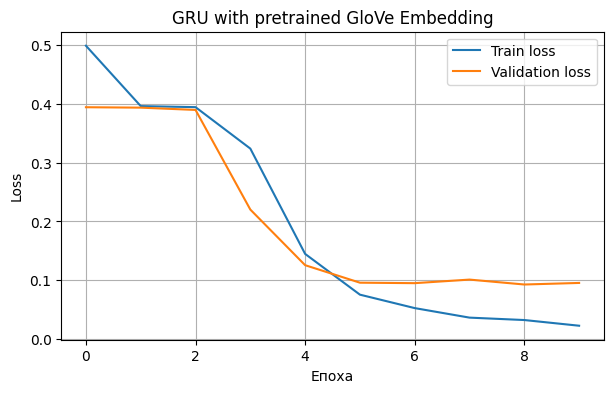

GloVe embedding: accuracy, precision, recall, F1 = (0.9874439461883409, 0.9655172413793104, 0.9395973154362416, 0.9523809523809523)
              precision    recall  f1-score   support

         ham     0.9907    0.9948    0.9928       966
        spam     0.9655    0.9396    0.9524       149

    accuracy                         0.9874      1115
   macro avg     0.9781    0.9672    0.9726      1115
weighted avg     0.9874    0.9874    0.9874      1115



,Підхід,Accuracy,Precision spam,Recall spam,F1 spam,"Час навчання, с"
0,GRU + random Embedding,0.950673,0.879032,0.731544,0.798535,2.465755
1,GRU + GloVe,0.987444,0.965517,0.939597,0.952381,2.473006


In [28]:
plot_history(gru_glove_hist,"GRU with pretrained GloVe Embedding")
glove_metrics=evaluate_text(gru_glove,test_text_loader)
print("GloVe embedding: accuracy, precision, recall, F1 =",glove_metrics[:4])
print(classification_report(glove_metrics[4],glove_metrics[5],target_names=["ham","spam"],digits=4))

text_comparison=pd.DataFrame({
    "Підхід":["GRU + random Embedding","GRU + GloVe"],
    "Accuracy":[rand_metrics[0],glove_metrics[0]],
    "Precision spam":[rand_metrics[1],glove_metrics[1]],
    "Recall spam":[rand_metrics[2],glove_metrics[2]],
    "F1 spam":[rand_metrics[3],glove_metrics[3]],
    "Час навчання, с":[gru_random_time,gru_glove_time]
})
display(text_comparison)

## 3.4 Підсумкове порівняння текстових моделей

Порівнюємо якість на одній тестовій вибірці. Pretrained embeddings можуть прискорити початкове навчання та дати корисне семантичне представлення слів, особливо коли навчальних прикладів мало. Однак перевага не гарантована: GloVe навчався на загальному текстовому корпусі, а SMS-повідомлення мають специфічну лексику, скорочення та помилки. Тому остаточний висновок робимо за метриками й кривими саме цього експерименту.

## 4. Загальні висновки

У ході виконання лабораторної роботи було розглянуто основні підходи до побудови, навчання та оцінювання нейронних мереж для трьох типів даних: табличних даних, зображень і текстів. Для реалізації моделей використовувалася бібліотека PyTorch. Також було досліджено криві навчання та порівняно результати нейронних мереж із різними підходами до навчання.

1. **Для табличних даних** було побудовано повнозв'язану нейронну мережу MLP на основі датасету кібербезпеки з лабораторної роботи №1. На тестовій вибірці модель отримала Accuracy = 0,8821 (88,21%), Precision для класу атак = 0,9891, Recall = 0,7444 та F1-score = 0,8495. За загальною точністю MLP практично не поступилася класичним алгоритмам, однак не перевищила результат Random Forest (0,8831). Криві навчання показали поступове зменшення навчальної та валідаційної помилок без виражених ознак перенавчання.

2. **Для класифікації зображень** було використано датасет Oxford-IIIT Pet Dataset, який містить 37 класів котів і собак. Було реалізовано два підходи: CNN, навчену з нуля, та попередньо натреновану ResNet18. Тестова Accuracy CNN становила 0,0605 (6,05%), тоді як ResNet18 досягла 0,7441 (74,41%). Таким чином, використання попередньо натренованої моделі забезпечило значно кращу якість класифікації та скоротило час навчання з 117,75 до 78,58 секунди. Аналіз кривих навчання показав недостатнє навчання CNN з нуля та ознаки перенавчання ResNet18, оскільки навчальна помилка продовжувала зменшуватися, тоді як валідаційна майже перестала покращуватися.

3. **Для класифікації текстів** було використано датасет SMS Spam Collection із повідомленнями двох категорій: звичайні повідомлення (ham) та спам (spam). Для класифікації було побудовано GRU-моделі з випадково ініціалізованими embedding та з попередньо навченими векторами GloVe. Модель із випадковими embedding отримала Accuracy = 0,9507 та F1-score для класу spam = 0,7985. Використання GloVe покращило результати до Accuracy = 0,9874 та F1-score = 0,9524. Це демонструє позитивний вплив попередньо навчених векторних представлень слів на якість текстової класифікації. При цьому час навчання обох моделей був практично однаковим.

4. **Аналіз learning curves** дозволив оцінити процес навчання моделей і порівняти помилки на тренувальних та валідаційних вибірках. Було встановлено, що характер зміни loss допомагає виявляти різні проблеми навчання: недостатнє навчання, перенавчання або стабільну збіжність моделі. Зокрема, для MLP спостерігалося стабільне зменшення обох видів помилки, тоді як для ResNet18 та GRU-моделей були помітні ознаки перенавчання.

5. **За результатами порівняння** можна зробити висновок, що нейронні мережі є гнучким інструментом машинного навчання, здатним виявляти складні закономірності в різних типах даних. Водночас їхня ефективність залежить від архітектури, обсягу навчальної вибірки, параметрів навчання та використання попередньо навчених моделей. Експерименти показали, що для невеликих табличних наборів класичні алгоритми можуть забезпечувати результати, співставні з нейронними мережами, а використання pretrained-моделей та embeddings може суттєво покращити якість класифікації зображень і текстів.

Отже, поставлену мету лабораторної роботи досягнуто: було отримано практичний досвід побудови та навчання нейронних мереж у PyTorch, досліджено особливості їхньої роботи з різними типами даних і порівняно ефективність альтернативних підходів до класифікації.